In [1]:
!nvidia-smi
!pip -q install efficientnet_pytorch kagglehub huggingface_hub opencv-python-headless scikit-learn

Sat Nov  7 10:10:31 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os, re, glob, time, random, getpass
import numpy as np, pandas as pd, torch

SEED = 0
D     = "/content/data2"      # downloaded files
PROC2 = "/content/proc2"      # processed images
WORK  = "/content/work"       # results (VM disk: download them before the session ends)
IMG_H, IMG_W = 1024, 640      # lower these if you run out of GPU memory
SLUG  = "bajcsiadel96/romanian-dense-breast-mammography-collection"
for d in (D, PROC2, WORK): os.makedirs(d, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

os.environ["KAGGLE_USERNAME"] = input("Kaggle username: ")
os.environ["KAGGLE_KEY"] = getpass.getpass("Kaggle API key: ")

In [3]:
import kagglehub

def fetch(rel):
    """Download one file of the Kaggle dataset (skips files already on disk). Returns its path, or 'ERR: ...'."""
    local = f"{D}/{rel}"
    if os.path.exists(local): return local
    try: return kagglehub.dataset_download(SLUG, path=rel)
    except Exception as e: return "ERR: " + str(e)[:300]

mp = fetch("metadata.csv"); assert os.path.exists(mp), mp
meta = pd.read_csv(mp)
feat = meta["Mass_Associated features"].fillna("")
meta["adenopathy"] = feat.str.contains(r"axill|adenop", case=False).astype(int)
meta["has_mass"] = meta["Mass_Present"].astype(str).str.lower().eq("yes").astype(int)
print("values in 'Mass_Associated features':", feat[feat != ""].value_counts().head(15).to_dict())

# one row per breast (Code = patient_session_class_side); duplicated rows are merged
sub = (meta.groupby("Code")
       .agg(Age=("Age", "first"), adenopathy=("adenopathy", "max"), has_mass=("has_mass", "max"),
            classification=("Classification", "first")).reset_index())
sub["patient"] = sub.Code.str[:4]
sub["name"] = sub.Code + "_MLO_MAM.png"      # 2D mammogram, MLO view (axilla is visible on MLO)

pos = sub[sub.adenopathy == 1]
print(f"\nbreasts: {len(sub)} | patients: {sub.patient.nunique()}")
print(f"adenopathy positives: {len(pos)} breasts, {pos.patient.nunique()} patients "
      f"| breasts with a mass: {int(sub.has_mass.sum())} | positives that also have a mass: {int(pos.has_mass.sum())}")
if pos.patient.nunique() < 30: print("WARNING: few positive patients; results will be very uncertain.")

values in 'Mass_Associated features': {'Calcifications': 34, 'Axillary adenopathy': 32, 'Calcifications, Axillary adenopathy': 15, 'Architectural distorsion': 9, 'Architectural distorsion, Calcifications': 5, 'Architectural distorsion, Axillary adenopathy': 5, 'Nipple retraction': 4, 'Nipple retraction, Axillary adenopathy': 3, 'Calcifications, Architectural distorsion': 1, 'Skin retraction': 1, 'Axillary adenopathy, Nipple retraction': 1, 'Calcifications, Nipple retraction': 1, 'Skin retraction, Architectural distorsion, Calcifications': 1, 'Skin retraction, Nipple retraction': 1, 'Architectural distorsion, Calcifications, Axillary adenopathy': 1}

breasts: 448 | patients: 244
adenopathy positives: 49 breasts, 47 patients | breasts with a mass: 251 | positives that also have a mass: 49


In [4]:
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

first = fetch("pngs/" + sub.name.iloc[0]); print(first)
assert os.path.exists(first), ("Single-file download failed. Paste me the line above. Fallback: "
                               "!kaggle datasets download -d " + SLUG + " -f pngs/" + sub.name.iloc[0])

with ThreadPoolExecutor(8) as ex:
    paths = list(tqdm(ex.map(lambda n: fetch("pngs/" + n), sub.name), total=len(sub)))
sub["src"] = paths
bad = ~sub.src.map(os.path.exists)
print(int(bad.sum()), "breasts without a fetchable MLO 2D PNG")
if bad.any(): print(sub[bad].name.head(5).tolist(), "|", sub[bad].src.iloc[0][:200])
sub = sub[~bad].reset_index(drop=True)
pos = sub[sub.adenopathy == 1]
print(f"usable: {len(sub)} breasts, {sub.patient.nunique()} patients | positives: {len(pos)} breasts, {pos.patient.nunique()} patients")

/content/data2/pngs/0001_1_B_R_MLO_MAM.png


  0%|          | 0/448 [00:00<?, ?it/s]

100%|██████████| 5.26M/5.26M [00:00<00:00, 12.4MB/s]





100%|██████████| 8.64M/8.64M [00:00<00:00, 12.6MB/s]



100%|██████████| 8.35M/8.35M [00:00<00:00, 15.0MB/s]
100%|██████████| 5.96M/5.96M [00:00<00:00, 13.0MB/s]








100%|██████████| 6.61M/6.61M [00:00<00:00, 11.5MB/s]
100%|██████████| 6.38M/6.38M [00:00<00:00, 10.7MB/s]




100%|██████████| 6.55M/6.55M [00:00<00:00, 9.90MB/s]






100%|██████████| 6.13M/6.13M [00:00<00:00, 12.9MB/s]


... (49 outputs left out)




100%|██████████| 5.33M/5.33M [00:00<00:00, 11.7MB/s]






100%|██████████| 3.74M/3.74M [00:00<00:00, 6.71MB/s]


100%|██████████| 3.79M/3.79M [00:00<00:00, 9.01MB/s]









100%|██████████| 3.52M/3.52M [00:00<00:00, 8.20MB/s]
100%|██████████| 3.95M/3.95M [00:00<00:00, 7.54MB/s]


100%|██████████| 4.26M/4.26M [00:00<00:00, 7.16MB/s]

7 breasts without a fetchable MLO 2D PNG
['0067_1_H_R_MLO_MAM.png', '0081_1_B_L_MLO_MAM.png', '0081_1_B_R_MLO_MAM.png', '0128_1_B_R_MLO_MAM.png', '0181_1_B_R_MLO_MAM.png'] | ERR: 404 Client Error.

Resource not found at URL: https://kaggle.com/datasets/bajcsiadel96/romanian-dense-breast-mammography-collection/versions/2
Please make sure you specified the correct resource 
usable: 441 breasts, 242 patients | positives: 49 breasts, 47 patients


first raw image: (4096, 3328, 4) uint8


  0%|          | 0/441 [00:00<?, ?it/s]

441 processed


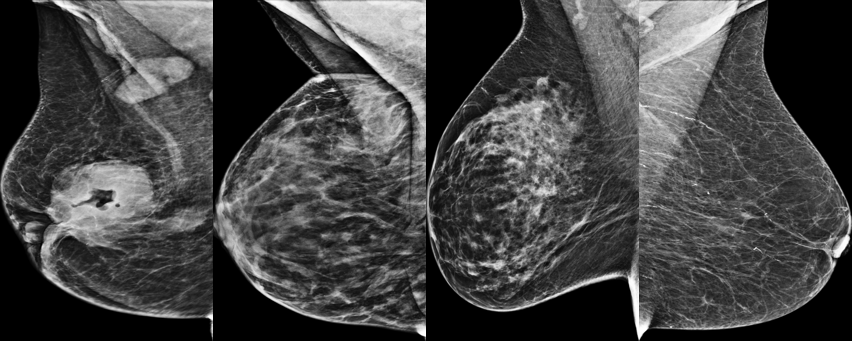

In [5]:
import cv2
from PIL import Image

def crop_resize(path, out):
    im = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if im is None: return False
    blur = cv2.GaussianBlur(im, (5, 5), 0)
    _, th = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    cnts, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if cnts:
        x, y, w, h = cv2.boundingRect(max(cnts, key=cv2.contourArea)); im = im[y:y + h, x:x + w]
    cv2.imwrite(out, cv2.resize(im, (IMG_W, IMG_H), interpolation=cv2.INTER_AREA)); return True

raw = cv2.imread(sub.src.iloc[0], cv2.IMREAD_UNCHANGED)
print("first raw image:", raw.shape, raw.dtype)

sub["proc_path"] = PROC2 + "/" + sub.Code + ".png"
with ThreadPoolExecutor(8) as ex:
    ok = list(tqdm(ex.map(lambda r: crop_resize(r.src, r.proc_path), sub.itertuples()), total=len(sub)))
sub = sub[np.array(ok)].reset_index(drop=True); print(len(sub), "processed")
sub.to_csv(f"{WORK}/manifest.csv", index=False)

pick = pd.concat([sub[sub.adenopathy == 1].head(2), sub[sub.adenopathy == 0].head(2)])
w, h = IMG_W // 3, IMG_H // 3
canvas = Image.new("L", (len(pick) * w, h))
for i, p in enumerate(pick.proc_path): canvas.paste(Image.open(p).resize((w, h)), (i * w, 0))
canvas   # left two: positives, right two: negatives

In [6]:
import torch.nn as nn
from huggingface_hub import hf_hub_download
from efficientnet_pytorch import EfficientNet

CKPT_FILE = "Pre-trained-checkpoints/b5-model-best-epoch-7.tar"
ckpt_path = hf_hub_download("shawn24/Mammo-CLIP", CKPT_FILE, local_dir=f"{WORK}/ckpt")
ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
sd = ck["model"]
enc_sd = {k.split("image_encoder.", 1)[1].removeprefix("model."): v
          for k, v in sd.items() if "image_encoder" in k}
print(len(enc_sd), "image-encoder tensors")

class Enc(nn.Module):
    """Returns the pooled 2048-d feature vector; property names match the fine-tuning code below."""
    def __init__(self, m):
        super().__init__()
        self.m = m
        self.num_features = m._conv_head.out_channels
    def forward(self, x):
        return self.m._avg_pooling(self.m.extract_features(x)).flatten(1)
    @property
    def blocks(self): return self.m._blocks
    @property
    def conv_head(self): return self.m._conv_head
    @property
    def bn2(self): return self.m._bn1

def _ok(k): return "num_batches_tracked" not in k and not k.startswith("_fc")

def load_backbone(init, verbose=True):
    if init == "mammoclip":
        m = EfficientNet.from_name("efficientnet-b5")
        miss, unexp = m.load_state_dict(enc_sd, strict=False)
        miss = [k for k in miss if _ok(k)]
        if verbose: print("missing (excluding _fc):", len(miss), miss[:4])
        assert not miss, "Weights did not load; paste the printed lines."
    elif init == "imagenet":
        m = EfficientNet.from_pretrained("efficientnet-b5")
    else:
        m = EfficientNet.from_name("efficientnet-b5")
    return Enc(m)

_ = load_backbone("mammoclip")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Pre-trained-checkpoints/b5-model-best-ep(…): reconstructing file:   0%|          |  0.00B / 1.65GB            

Pre-trained-checkpoints/b5-model-best-ep(…): downloading bytes:           |  0.00B            

852 image-encoder tensors
missing (excluding _fc): 0 []


In [7]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score

MEAN, STD = 0.3089279, 0.25053555408335154   # defaults from the Mammo-CLIP repo

y  = sub.adenopathy.values
g  = sub.patient.values
hm = sub.has_mass.values.astype(bool)
K  = int(min(5, sub[sub.adenopathy == 1].patient.nunique()))
assert K >= 2, "Need at least 2 positive patients for cross-validation"
def folds(seed): return list(StratifiedGroupKFold(K, shuffle=True, random_state=seed).split(np.zeros(len(y)), y, g))

@torch.no_grad()
def extract(bb, paths, bs=4):
    out = []
    for i in range(0, len(paths), bs):
        x = torch.stack([torch.from_numpy(np.asarray(Image.open(p).convert("L"), dtype=np.float32) / 255.0)
                         for p in paths[i:i + bs]])
        x = ((x - MEAN) / STD).unsqueeze(1).repeat(1, 3, 1, 1).cuda()
        with torch.autocast("cuda", dtype=torch.float16):
            out.append(bb(x).float().cpu())
    return torch.cat(out).numpy()

def get_features(init):
    bb = load_backbone(init).cuda().eval()
    X = extract(bb, sub.proc_path.tolist()); del bb; torch.cuda.empty_cache(); return X

def boot_ci(yy, pp, gg, n=1000):
    rng = np.random.default_rng(0); ug = np.unique(gg); idx = {u: np.where(gg == u)[0] for u in ug}; out = []
    for _ in range(n):   # resample patients, not breasts
        ii = np.concatenate([idx[u] for u in rng.choice(ug, len(ug))])
        if len(np.unique(yy[ii])) > 1: out.append(roc_auc_score(yy[ii], pp[ii]))
    return np.percentile(out, [2.5, 97.5])

def summarize(p, name, per_seed=None):
    lo, hi = boot_ci(y, p, g)
    s = (f"{name:24s} all breasts:   AUC {roc_auc_score(y, p):.3f} [{lo:.3f}, {hi:.3f}] "
         f"| AP {average_precision_score(y, p):.3f} (chance {y.mean():.3f})")
    if per_seed: s += f" | seed range {min(per_seed):.3f}-{max(per_seed):.3f}"
    if len(np.unique(y[hm])) > 1:
        lo2, hi2 = boot_ci(y[hm], p[hm], g[hm])
        s += (f"\n{'':24s} breasts w/ mass: AUC {roc_auc_score(y[hm], p[hm]):.3f} [{lo2:.3f}, {hi2:.3f}] "
              f"(n={int(hm.sum())}, positives={int(y[hm].sum())})")
    print(s)

def cv_probe(X, name, C=0.01, seeds=(0, 1, 2)):
    oofs = []
    for s in seeds:
        oof = np.zeros(len(y))
        for tr, te in folds(s):
            sc = StandardScaler().fit(X[tr])
            clf = LogisticRegression(C=C, class_weight="balanced", max_iter=3000).fit(sc.transform(X[tr]), y[tr])
            oof[te] = clf.predict_proba(sc.transform(X[te]))[:, 1]
        oofs.append(oof)
    p = np.mean(oofs, axis=0)
    summarize(p, name, per_seed=[roc_auc_score(y, o) for o in oofs])
    return p

print(f"folds: {K} | breasts: {len(y)} | positives: {int(y.sum())} ({y.mean():.1%})")
print("trivial baselines (no image): has_mass alone AUC =", round(roc_auc_score(y, hm), 3),
      "| age alone AUC =", round(roc_auc_score(y, sub.Age.fillna(sub.Age.median())), 3))

RESULTS = {}
RESULTS["lp_mammoclip"] = cv_probe(get_features("mammoclip"), "LP Mammo-CLIP")
RESULTS["lp_imagenet"]  = cv_probe(get_features("imagenet"),  "LP ImageNet")

folds: 5 | breasts: 441 | positives: 49 (11.1%)
trivial baselines (no image): has_mass alone AUC = 0.747 | age alone AUC = 0.467
missing (excluding _fc): 0 []
LP Mammo-CLIP            all breasts:   AUC 0.838 [0.773, 0.895] | AP 0.475 (chance 0.111) | seed range 0.815-0.844
                         breasts w/ mass: AUC 0.787 [0.709, 0.857] (n=247, positives=49)
Downloading: "https://github.com/lukemelas/EfficientNet-PyTorch/releases/download/1.0/efficientnet-b5-b6417697.pth" to /root/.cache/torch/hub/checkpoints/efficientnet-b5-b6417697.pth


100%|██████████| 117M/117M [00:02<00:00, 50.5MB/s] 


Loaded pretrained weights for efficientnet-b5
LP ImageNet              all breasts:   AUC 0.743 [0.669, 0.812] | AP 0.272 (chance 0.111) | seed range 0.708-0.757
                         breasts w/ mass: AUC 0.711 [0.631, 0.790] (n=247, positives=49)


In [8]:
import torchvision.transforms.functional as TF
from torchvision.transforms import v2 as T
from torch.utils.data import DataLoader

class DS1(torch.utils.data.Dataset):
    def __init__(self, df, train):
        self.df, self.train = df.reset_index(drop=True), train
        self.aug = T.Compose([T.RandomHorizontalFlip(),
                              T.RandomAffine(degrees=7, translate=(0.03, 0.03), scale=(0.95, 1.05)),
                              T.ColorJitter(brightness=0.15, contrast=0.15)])
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        im = Image.open(r.proc_path).convert("L")
        if self.train: im = self.aug(im)
        x = (TF.to_tensor(im) - MEAN) / STD
        return x.repeat(3, 1, 1), torch.tensor(float(r.adenopathy))

def set_bn_eval(m):
    for mod in m.modules():
        if isinstance(mod, nn.modules.batchnorm._BatchNorm): mod.eval()

def ft_fold(tr_df, te_df, epochs=8, bs=2, accum=4, lr_head=1e-3, lr_bb=2e-5):
    bb = load_backbone("mammoclip", verbose=False)
    model = nn.Sequential(bb, nn.Linear(bb.num_features, 1)).cuda()
    for p in bb.parameters(): p.requires_grad = False
    tp = [p for m in (bb.blocks[-2:], bb.conv_head, bb.bn2) for p in m.parameters()]
    for p in tp: p.requires_grad = True
    opt = torch.optim.AdamW([{"params": model[1].parameters(), "lr": lr_head},
                             {"params": tp, "lr": lr_bb}], weight_decay=1e-2)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    pos = float(tr_df.adenopathy.mean())
    crit = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([min((1 - pos) / max(pos, 1e-3), 10.0)], device="cuda"))
    scaler = torch.amp.GradScaler("cuda")
    dl = DataLoader(DS1(tr_df, True), batch_size=bs, shuffle=True, num_workers=2, drop_last=True)
    for ep in range(epochs):
        model.train(); set_bn_eval(bb); opt.zero_grad()
        for i, (x, yb) in enumerate(dl):
            x, yb = x.cuda(), yb.cuda()
            with torch.autocast("cuda", dtype=torch.float16):
                loss = crit(model(x).squeeze(1).float(), yb) / accum
            scaler.scale(loss).backward()
            if (i + 1) % accum == 0:
                scaler.step(opt); scaler.update(); opt.zero_grad()
        sched.step()
    model.eval(); ps = []
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
        for x, _ in DataLoader(DS1(te_df, False), batch_size=4, num_workers=2):
            ps.append(torch.sigmoid(model(x.cuda()).squeeze(1).float()).cpu())
    del model, opt; torch.cuda.empty_cache()
    return torch.cat(ps).numpy()

oof = np.zeros(len(y))
for k, (tr, te) in enumerate(folds(SEED)):
    t0 = time.time()
    oof[te] = ft_fold(sub.iloc[tr], sub.iloc[te])
    print(f"fold {k + 1}/{K} done in {time.time() - t0:.0f}s")
RESULTS["ft_mammoclip"] = oof
summarize(oof, "FT Mammo-CLIP (1 seed)")

fold 1/5 done in 154s
fold 2/5 done in 153s
fold 3/5 done in 150s
fold 4/5 done in 151s
fold 5/5 done in 149s
FT Mammo-CLIP (1 seed)   all breasts:   AUC 0.786 [0.722, 0.850] | AP 0.384 (chance 0.111)
                         breasts w/ mass: AUC 0.714 [0.636, 0.793] (n=247, positives=49)


441 breasts, 242 patients | positives: 49 breasts, 47 patients | breasts with a mass: 247


Model,"AUC, all breasts","AUC, breasts with a mass",AP (chance 0.11),Sensitivity at 10% false alarms
"Mammo-CLIP, frozen + linear probe","0.838 [0.773, 0.895]","0.787 [0.709, 0.857]",0.475000,0.410000
"Mammo-CLIP, fine-tuned","0.786 [0.722, 0.850]","0.714 [0.636, 0.793]",0.384000,0.330000
"ImageNet, frozen + linear probe","0.743 [0.669, 0.812]","0.711 [0.631, 0.790]",0.272000,0.330000
No image: has a mass (yes/no),"0.747 [0.722, 0.773]",n/a (same score for all),0.198000,-
No image: patient age,"0.467 [0.380, 0.554]","0.528 [0.433, 0.617]",0.118000,0.120000


AUC: 0.5 = chance, 1.0 = perfect. [..] = 95% interval (resampling patients). AP = average precision. Sensitivity is measured among breasts with a mass.


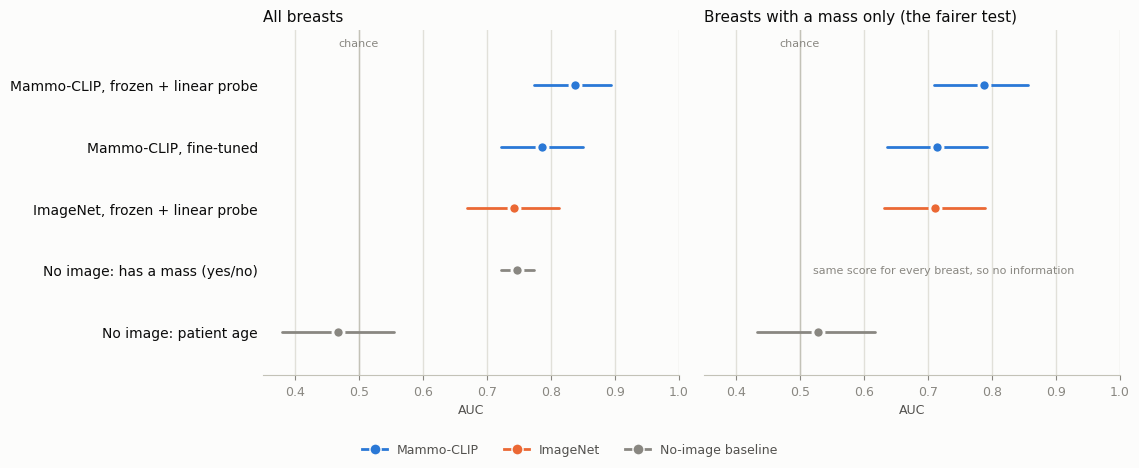

In [10]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve

# ---------- inputs (already in memory after the earlier cells) ----------
y   = sub.adenopathy.values.astype(int)
g   = sub.patient.values
hm  = sub.has_mass.values.astype(bool)
age = sub.Age.fillna(sub.Age.median()).values.astype(float)

NAMES = {   # RESULTS key -> (name shown, pretraining source)
    "lp_mammoclip": ("Mammo-CLIP, frozen + linear probe", "Mammo-CLIP"),
    "ft_mammoclip": ("Mammo-CLIP, fine-tuned",            "Mammo-CLIP"),
    "lp_imagenet":  ("ImageNet, frozen + linear probe",   "ImageNet"),
    "ft_imagenet":  ("ImageNet, fine-tuned",              "ImageNet"),
}
models = [(*NAMES.get(k, (k, "Other")), np.asarray(v, float)) for k, v in RESULTS.items()]
models += [("No image: has a mass (yes/no)", "Baseline", hm.astype(float)),
           ("No image: patient age",         "Baseline", age)]

def ci(yy, pp, gg, n=1000):
    """95% interval from resampling patients (same method as the earlier cells)."""
    rng = np.random.default_rng(0)
    ug = np.unique(gg); idx = {u: np.where(gg == u)[0] for u in ug}; out = []
    for _ in range(n):
        ii = np.concatenate([idx[u] for u in rng.choice(ug, len(ug))])
        if len(np.unique(yy[ii])) > 1: out.append(roc_auc_score(yy[ii], pp[ii]))
    return np.percentile(out, [2.5, 97.5])

# ---------- compute ----------
rows = []
for name, src, p in models:
    if np.isnan(p).any(): print(f"skipping '{name}': some predictions are missing"); continue
    a = roc_auc_score(y, p); alo, ahi = ci(y, p, g)
    if np.ptp(p[hm]) > 0:                       # score varies among breasts that have a mass
        m = roc_auc_score(y[hm], p[hm]); mlo, mhi = ci(y[hm], p[hm], g[hm])
        fpr, tpr, _ = roc_curve(y[hm], p[hm]); sens = float(np.interp(0.10, fpr, tpr))
    else:
        m = mlo = mhi = sens = np.nan
    rows.append(dict(name=name, src=src, auc=a, alo=alo, ahi=ahi, mauc=m, mlo=mlo, mhi=mhi,
                     ap=average_precision_score(y, p), sens=sens))
res = pd.DataFrame(rows)
res = pd.concat([res[res.src != "Baseline"].sort_values("mauc", ascending=False),
                 res[res.src == "Baseline"]], ignore_index=True)

# ---------- table ----------
def fmt(v, lo, hi): return "n/a (same score for all)" if np.isnan(v) else f"{v:.3f}  [{lo:.3f}, {hi:.3f}]"
show = pd.DataFrame({
    "Model": res.name,
    "AUC, all breasts": [fmt(*t) for t in zip(res.auc, res.alo, res.ahi)],
    "AUC, breasts with a mass": [fmt(*t) for t in zip(res.mauc, res.mlo, res.mhi)],
    f"AP (chance {y.mean():.2f})": res.ap.round(3),
    "Sensitivity at 10% false alarms": res.sens.round(2).astype(object).where(res.sens.notna(), "-"),
})
print(f"{len(y)} breasts, {len(np.unique(g))} patients | positives: {int(y.sum())} breasts, "
      f"{len(np.unique(g[y == 1]))} patients | breasts with a mass: {int(hm.sum())}")
try: display(show.style.hide(axis="index"))
except Exception: print(show.to_string(index=False))
print("AUC: 0.5 = chance, 1.0 = perfect. [..] = 95% interval (resampling patients). "
      "AP = average precision. Sensitivity is measured among breasts with a mass.")
try: res.to_csv(f"{WORK}/summary.csv", index=False)
except Exception: pass

# ---------- chart: dot = result, line = 95% interval ----------
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
COL = {"Mammo-CLIP": "#2a78d6", "ImageNet": "#eb6834", "Baseline": "#898781", "Other": "#1baf7a"}
n = len(res); ypos = np.arange(n)[::-1]            # best model on top
lows = np.concatenate([res.alo.values, res.mlo.dropna().values])
xmin = min(0.4, np.floor((lows.min() - 0.02) * 20) / 20)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 0.5 * n + 2.2), sharey=True, facecolor=SURFACE)
panels = [("All breasts", "auc", "alo", "ahi"),
          ("Breasts with a mass only (the fairer test)", "mauc", "mlo", "mhi")]
for ax, (title, c, lo, hi) in zip(axes, panels):
    ax.set_facecolor(SURFACE)
    ax.axvline(0.5, color=AXIS, lw=1, zorder=1)
    ax.text(0.5, n - 0.4, "chance", color=MUTED, fontsize=8, ha="center", va="bottom")
    for yp, r in zip(ypos, res.itertuples()):
        v, l, h, col = getattr(r, c), getattr(r, lo), getattr(r, hi), COL.get(r.src, COL["Other"])
        if np.isnan(v):
            ax.text(0.52, yp, "same score for every breast, so no information", color=MUTED, fontsize=8, va="center")
            continue
        ax.plot([l, h], [yp, yp], color=col, lw=2, solid_capstyle="round", zorder=2)
        ax.plot([v], [yp], "o", ms=8, color=col, mec=SURFACE, mew=2, zorder=3)
    ax.set_xlim(xmin, 1.0); ax.set_ylim(-0.7, n - 0.1)
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.set_xlabel("AUC", color=INK2, fontsize=9)
    ax.set_axisbelow(True); ax.xaxis.grid(True, color=GRID, lw=1)
    for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)
    ax.tick_params(axis="x", colors=MUTED, labelsize=9); ax.tick_params(axis="y", length=0)
axes[0].set_yticks(ypos); axes[0].set_yticklabels(res.name, color=INK, fontsize=10)

order = [s for s in ("Mammo-CLIP", "ImageNet", "Other", "Baseline") if s in set(res.src)]
lab = {"Baseline": "No-image baseline", "Other": "Other"}
handles = [Line2D([0], [0], marker="o", color=COL[s], lw=2, ms=8, mec=SURFACE, label=lab.get(s, s)) for s in order]
fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False, labelcolor=INK2, fontsize=9)
fig.tight_layout(rect=(0, 0.07, 1, 1))
try: fig.savefig(f"{WORK}/summary.png", dpi=150, facecolor=SURFACE, bbox_inches="tight")
except Exception: pass
plt.show()